# Lab 3 : analyse des résultats

Ce notebook lit les CSV du dossier `results/`. Ces fichiers sont produits par GitHub Actions (workflow `experiments.yml`), sur 3 machines : Ubuntu x86, Ubuntu ARM et macOS ARM.

Le notebook ne lance aucune expérience, il lit juste les résultats.

Pour le relancer : `pip install -r requirements-notebook.txt`, puis *Restart Kernel and Run All Cells*.

In [1]:
import glob

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.precision", 2)

df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob("results/results_*.csv"))], ignore_index=True)
causal = pd.concat([pd.read_csv(f) for f in sorted(glob.glob("results/causal_*.csv"))], ignore_index=True)

# une colonne pour savoir sur quelle machine ça a tourné
df["machine"] = df["os"] + " " + df["arch"]
causal["machine"] = causal["os"] + " " + causal["arch"]
df["Compilateur"] = df["Compilateur"].fillna("aucun")

FACTEURS = ["Repetitions", "Language", "Propriete", "Librairie", "Precision", "Intervalle", "Compilateur", "machine"]
print(len(df), "exécutions,", df["config_id"].nunique(), "configurations")
df.head()

485 exécutions, 64 configurations


,config_id,origin_of_config,Repetitions,Language,Systeme,Propriete,Librairie,Precision,Intervalle,Compilateur,...,percentage,os,os_version,arch,python,node,commit,compiler_version,cflags,machine
0,llm.chatgpt.js,anchor,10000,JavaScript,MacOS,Associativite,random,double,Max100,aucun,...,75.17,Darwin,25.6.0,arm64,3.12.10,v24.22.2,995f4e1,NaN,NaN,Darwin arm64
1,llm.chatgpt.js,anchor,10000,JavaScript,MacOS,Associativite,random,double,Max100,aucun,...,74.32,Darwin,25.6.0,arm64,3.12.10,v24.22.2,995f4e1,NaN,NaN,Darwin arm64
2,llm.chatgpt.js,anchor,10000,JavaScript,MacOS,Associativite,random,double,Max100,aucun,...,74.55,Darwin,25.6.0,arm64,3.12.10,v24.22.2,995f4e1,NaN,NaN,Darwin arm64
3,llm.chatgpt.js,anchor,10000,JavaScript,MacOS,Associativite,random,double,Max100,aucun,...,74.28,Darwin,25.6.0,arm64,3.12.10,v24.22.2,995f4e1,NaN,NaN,Darwin arm64
4,llm.chatgpt.js,anchor,10000,JavaScript,MacOS,Associativite,random,double,Max100,aucun,...,74.96,Darwin,25.6.0,arm64,3.12.10,v24.22.2,995f4e1,NaN,NaN,Darwin arm64


## 1. Ce qu'on a lancé

Notre feature model (`fm/experiment.uvl`) a 192 configurations. On en a tiré 60 au hasard (seed 1), et on a ajouté nos 4 programmes des labs 1 et 2. Ça fait 64 configurations.

Chaque configuration est lancée 5 fois, parce que le résultat est aléatoire. Les lignes `Ubuntu` tournent sur les deux runners Ubuntu (x86 et ARM), les lignes `MacOS` sur le runner macOS.

In [2]:
df.groupby("machine").agg(configurations=("config_id", "nunique"), executions=("percentage", "size"))

,configurations,executions
machine,,
Darwin arm64,31,155
Linux aarch64,33,165
Linux x86_64,33,165


## 2. Est-ce que le résultat bouge d'une exécution à l'autre ?

Oui. On regarde l'écart-type entre les 5 exécutions d'une même configuration, selon le nombre de répétitions.

In [3]:
ecart = (df.groupby(["config_id", "machine", "Repetitions"])["percentage"].std()
           .groupby("Repetitions").agg(["mean", "max"]))
ecart.columns = ["écart-type moyen", "écart-type max"]
ecart

,écart-type moyen,écart-type max
Repetitions,,
10000,0.38,0.68
100000,0.14,0.23
1000000,0.04,0.08


Plus il y a de répétitions, moins le résultat bouge. Avec 10 000 répétitions le pourcentage varie d'environ 0,4 point entre deux exécutions, avec 1 000 000 il ne bouge presque plus.

C'est normal : on estime une proportion, donc l'erreur diminue comme 1/√n. Le nombre de répétitions ne change pas la valeur du résultat, il change juste sa précision.

Donc si on relance le workflow sur le même commit, on n'a pas exactement les mêmes chiffres (les tirages ne sont pas fixés par une graine), mais on reste dans cet écart.

## 3. Effet de chaque facteur

Pour chaque facteur, la moyenne du pourcentage selon sa valeur. On sépare les deux propriétés parce qu'elles n'ont pas du tout le même niveau.

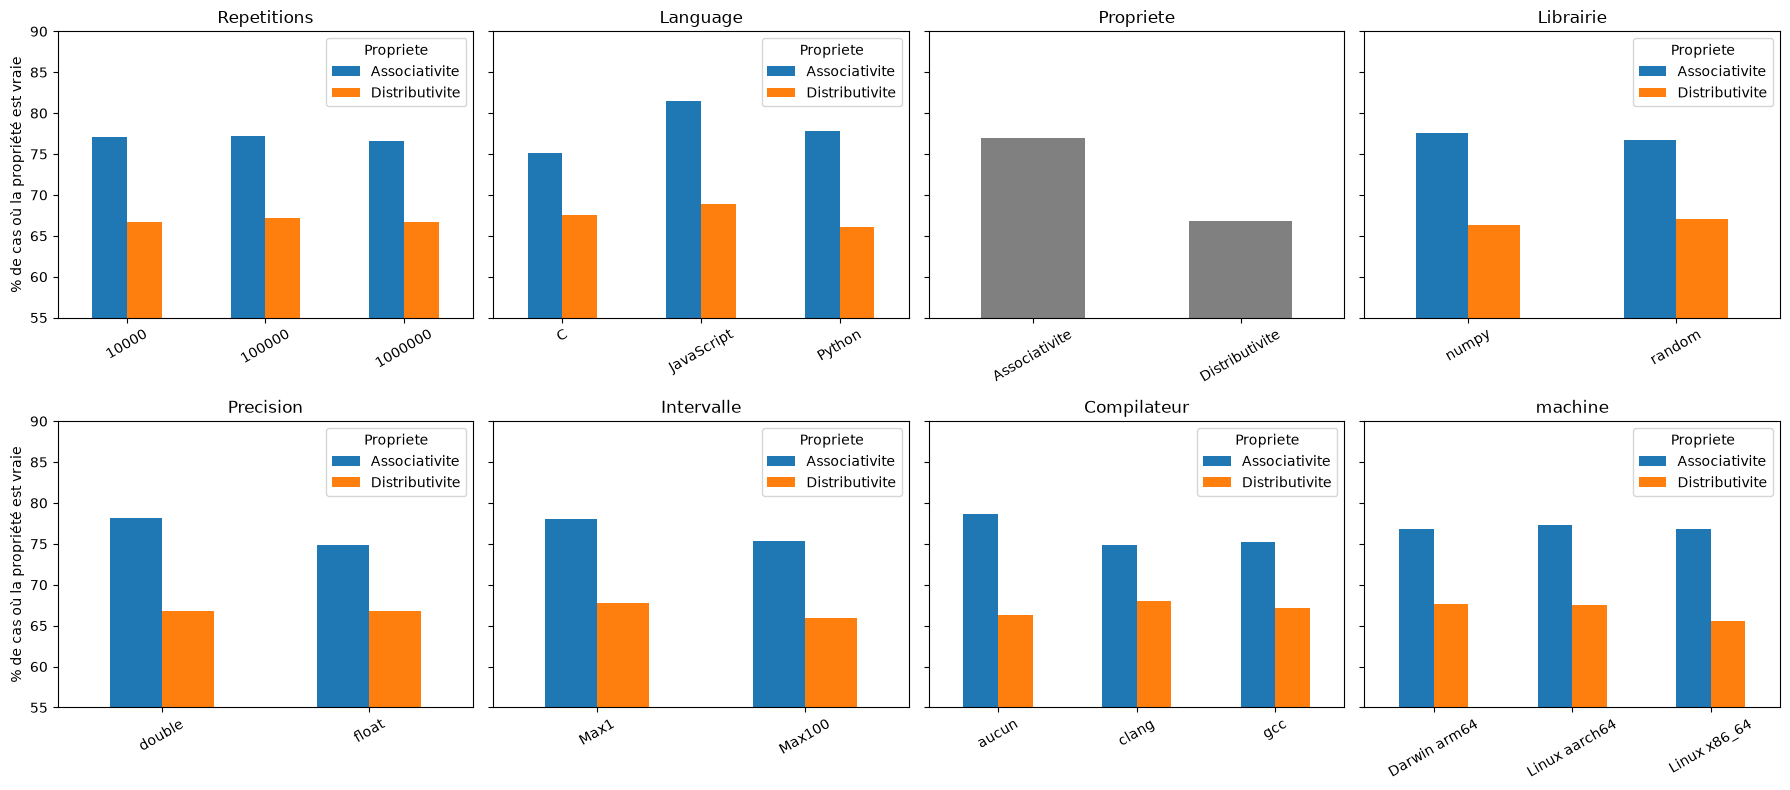

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, facteur in zip(axes.flat, FACTEURS):
    if facteur == "Propriete":
        df.groupby("Propriete")["percentage"].mean().plot.bar(ax=ax, color="gray")
    else:
        df.groupby([facteur, "Propriete"])["percentage"].mean().unstack().plot.bar(ax=ax)
    ax.set_title(facteur)
    ax.set_xlabel("")
    ax.set_ylim(55, 90)
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].set_ylabel("% de cas où la propriété est vraie")
axes[1, 0].set_ylabel("% de cas où la propriété est vraie")
plt.tight_layout()
plt.show()

In [5]:
for facteur in FACTEURS:
    if facteur != "Propriete":
        display(df.groupby([facteur, "Propriete"])["percentage"].agg(["mean", "std", "count"]).unstack("Propriete"))

mean                          std                 \
Propriete   Associativite Distributivite Associativite Distributivite   
Repetitions                                                             
10000               77.03          66.67          3.54           2.32   
100000              77.19          67.16          3.63           2.23   
1000000             76.55          66.71          3.45           2.26   

                    count                 
Propriete   Associativite Distributivite  
Repetitions                               
10000                 100             65  
100000                 90             60  
1000000                65            105

mean                          std                 \
Propriete  Associativite Distributivite Associativite Distributivite   
Language                                                               
C                  75.09          67.55          1.13           2.19   
JavaScript         81.53          68.93          3.14           0.05   
Python             77.80          66.03          3.97           2.12   

                   count                 
Propriete  Associativite Distributivite  
Language                                 
C                    120            100  
JavaScript            30             10  
Python               105            120

mean                          std                 \
Propriete Associativite Distributivite Associativite Distributivite   
Librairie                                                             
numpy             77.54          66.31          3.90           2.18   
random            76.68          67.02          3.33           2.28   

                  count                 
Propriete Associativite Distributivite  
Librairie                               
numpy                85             65  
random              170            165

mean                          std                 \
Propriete Associativite Distributivite Associativite Distributivite   
Precision                                                             
double            78.11          66.84          3.91           2.27   
float             74.88          66.76          0.96           2.29   

                  count                 
Propriete Associativite Distributivite  
Precision                               
double              165            165  
float                90             65

mean                          std                 \
Propriete  Associativite Distributivite Associativite Distributivite   
Intervalle                                                             
Max1               78.05          67.83          4.10           2.01   
Max100             75.29          65.97          1.19           2.13   

                   count                 
Propriete  Associativite Distributivite  
Intervalle                               
Max1                 155            105  
Max100               100            125

mean                          std                 \
Propriete   Associativite Distributivite Associativite Distributivite   
Compilateur                                                             
aucun               78.63          66.25          4.09           2.18   
clang               74.85          68.05          0.31           2.02   
gcc                 75.26          67.21          1.44           2.25   

                    count                 
Propriete   Associativite Distributivite  
Compilateur                               
aucun                 135            130  
clang                  50             40  
gcc                    70             60

mean                          std                 \
Propriete     Associativite Distributivite Associativite Distributivite   
machine                                                                   
Darwin arm64          76.84          67.61          3.62           2.20   
Linux aarch64         77.27          67.48          3.48           2.15   
Linux x86_64          76.81          65.59          3.55           1.90   

                      count                 
Propriete     Associativite Distributivite  
machine                                     
Darwin arm64             95             60  
Linux aarch64            80             85  
Linux x86_64             80             85

Ce qu'on voit :

- **La propriété** a le plus gros effet : l'associativité est vraie plus souvent que la distributivité.
- **La précision et l'intervalle** ont un gros effet aussi : en `float`, ou avec des nombres entre 0 et 100, le pourcentage baisse.
- **Le langage** a l'air d'avoir un effet (le C est plus bas), mais on va voir que ce n'est pas vraiment le langage.
- **Le nombre de répétitions et la librairie** ne changent presque rien à la moyenne. Pareil pour gcc ou clang (la colonne `aucun`, c'est Python et JavaScript).
- **La machine** ne change presque rien, sauf pour le C sur ARM (partie 6).

## 4. Arbre de décision

Pour vérifier ça de façon plus systématique, on entraîne un arbre de décision qui prédit le pourcentage à partir des facteurs. Les facteurs qu'il utilise en premier sont ceux qui comptent le plus.

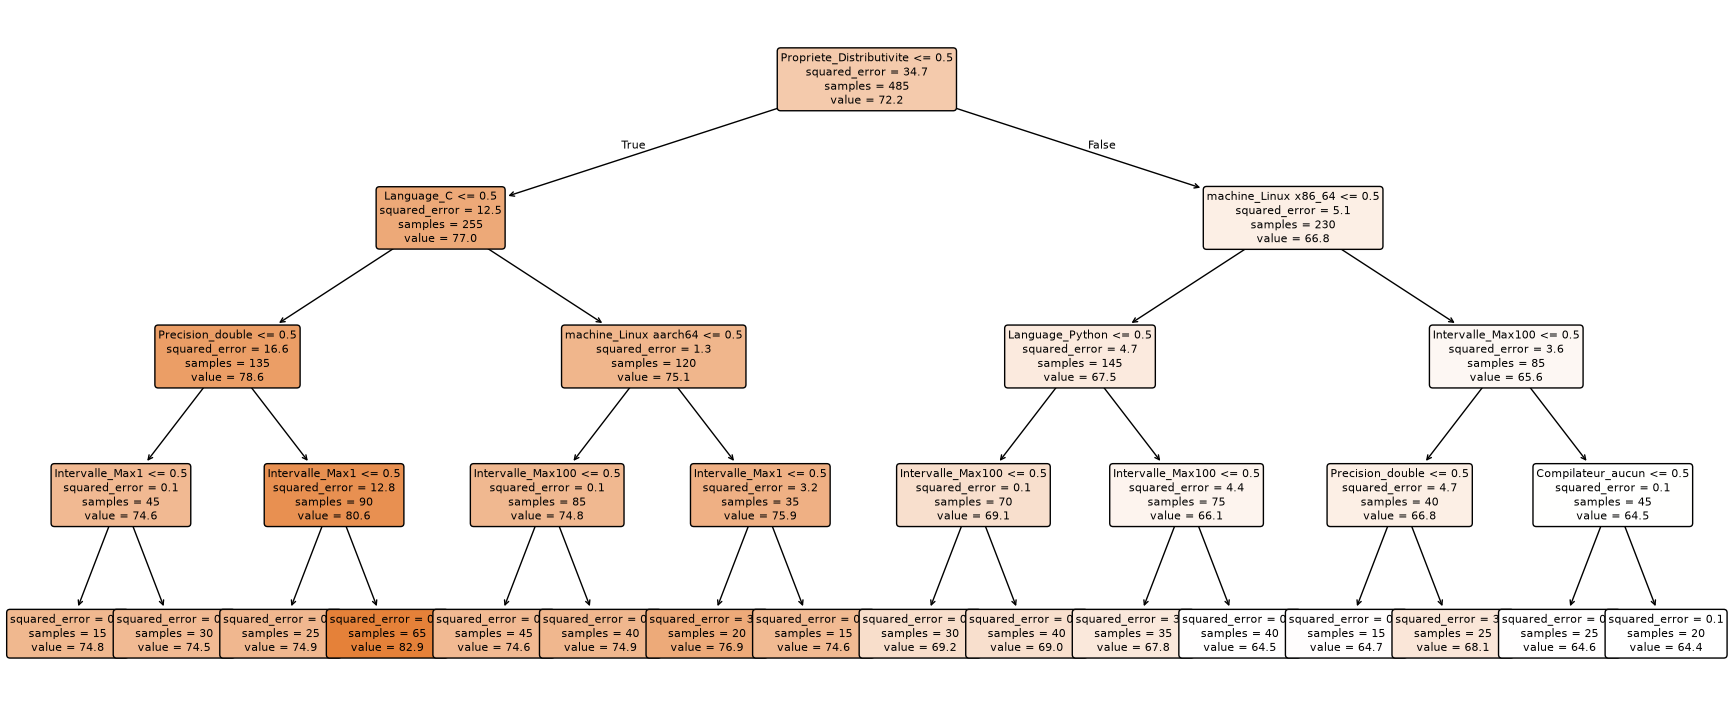

,importance
Propriete,0.75
Intervalle,0.09
Precision,0.07
Language,0.07
machine,0.01
Compilateur,0.00
Librairie,0.00
Repetitions,0.00


In [6]:
X = pd.get_dummies(df[FACTEURS].astype(str))
arbre = DecisionTreeRegressor(max_depth=4, random_state=0).fit(X, df["percentage"])

plt.figure(figsize=(22, 9))
plot_tree(arbre, feature_names=list(X.columns), filled=True, rounded=True, precision=1, fontsize=8)
plt.show()

importance = pd.Series(arbre.feature_importances_, index=X.columns)
importance.groupby(lambda nom: nom.split("_")[0]).sum().sort_values(ascending=False).round(3).to_frame("importance")

L'arbre confirme : il coupe d'abord sur la propriété, puis sur la façon dont les nombres sont fabriqués (précision, intervalle, langage). Les répétitions ne servent presque pas.

## 5. Le vrai facteur : comment les nombres sont fabriqués

En regardant les tableaux, on a remarqué qu'il n'y a en fait que deux niveaux pour chaque propriété. On a une explication.

`random.random()` en Python et `Math.random()` en JavaScript tirent un entier de 53 bits et le divisent par 2^53. Les nombres obtenus sont tous des multiples de 2^-53 : ils sont sur une grille. Un petit nombre sur cette grille a des zéros à la fin de sa mantisse, donc les additions tombent plus souvent juste, sans arrondi.

Dans les autres cas, la mantisse est remplie jusqu'au dernier bit :

- en C, `rand() / RAND_MAX` divise par 2^31 - 1, qui n'est pas une puissance de 2 ;
- quand on multiplie par 100 pour avoir des nombres entre 0 et 100 ;
- en `float`, parce qu'on arrondit à 24 bits.

Là il y a plus d'arrondis, donc la propriété est vraie moins souvent.

On range chaque configuration dans un des deux groupes :

In [7]:
grille = (df["Precision"] == "double") & (df["Intervalle"] == "Max1") & (df["Language"] != "C")
df["nombres"] = grille.map({True: "sur la grille 2^-53", False: "mantisse pleine"})

df.groupby(["Propriete", "nombres"])["percentage"].agg(["mean", "std", "min", "max", "count"])

mean   std    min    max  count
Propriete      nombres                                              
Associativite  mantisse pleine      74.95  0.94  73.89  79.10    190
               sur la grille 2^-53  82.85  0.26  81.96  83.53     65
Distributivite mantisse pleine      66.22  2.22  63.58  70.19    180
               sur la grille 2^-53  68.98  0.20  68.50  69.82     50

À l'intérieur d'un groupe, le pourcentage ne bouge presque plus, quel que soit le langage ou la librairie. Donc le langage n'est pas la cause : c'est juste que le C n'a pas le même générateur.

La seule exception est le C sur ARM, qu'on regarde juste après (c'est lui qui fait monter l'écart-type du groupe « mantisse pleine »).

### Ça explique nos résultats des labs 1 et 2

In [8]:
labs = pd.DataFrame({
    "programme": ["C (lab 1)", "Python (lab 1)", "JavaScript ChatGPT (lab 2)", "Python Gemini (lab 3)"],
    "config_id": ["tp1.c", "tp1.python", "llm.chatgpt.js", "llm.gemini.python"],
    "résultat d'origine": [75, 82.54, 74.82, 82.75],
})
ancres = df[df["origin_of_config"] == "anchor"].pivot_table(
    index=["config_id", "nombres"], columns="machine", values="percentage", aggfunc="mean").reset_index()
labs.merge(ancres, on="config_id")

,programme,config_id,résultat d'origine,nombres,Darwin arm64,Linux aarch64,Linux x86_64
0,C (lab 1),tp1.c,75.00,mantisse pleine,NaN,78.65,74.88
1,Python (lab 1),tp1.python,82.54,sur la grille 2^-53,83.12,NaN,NaN
2,JavaScript ChatGPT (lab 2),llm.chatgpt.js,74.82,mantisse pleine,74.66,NaN,NaN
3,Python Gemini (lab 3),llm.gemini.python,82.75,sur la grille 2^-53,NaN,82.74,82.82


On retrouve les valeurs d'origine (chaque programme tourne sur le système où il avait été lancé, d'où les cases vides). Et on comprend l'écart entre nos programmes :

- notre C du lab 1 est en `float` entre 0 et 100, donc mantisse pleine : environ 75 % ;
- le JavaScript de ChatGPT multiplie par 100, donc mantisse pleine aussi : environ 75 % ;
- les deux programmes Python utilisent `random()` directement, donc la grille : environ 83 %.

Ce n'était pas une histoire de langage ou d'OS, mais de comment chaque programme tire ses nombres.

Une surprise quand même : notre C donne environ 78,7 % sur Ubuntu ARM, au lieu de 75 % sur x86. On l'explique dans la partie suivante.

## 6. Effet de la machine

On compare les 3 runners. Ubuntu x86 et Ubuntu ARM ont le même OS mais pas le même processeur. Ubuntu ARM et macOS ont le même type de processeur mais pas le même OS.

In [9]:
df["cas"] = df["Language"].where(df["Language"] == "C", "Python / JavaScript")
display(df.pivot_table(index=["Propriete", "nombres", "cas"], columns="machine", values="percentage", aggfunc="mean"))

# le détail pour le C
df[df["Language"] == "C"].pivot_table(index=["Propriete", "Intervalle", "Compilateur"], columns="machine",
                                      values="percentage", aggfunc="mean")

machine                                                 Darwin arm64  \
Propriete      nombres             cas                                 
Associativite  mantisse pleine     C                           74.70   
                                   Python / JavaScript         74.67   
               sur la grille 2^-53 Python / JavaScript         82.85   
Distributivite mantisse pleine     C                           69.21   
                                   Python / JavaScript         64.54   
               sur la grille 2^-53 Python / JavaScript         68.93   

machine                                                 Linux aarch64  \
Propriete      nombres             cas                                  
Associativite  mantisse pleine     C                            75.91   
                                   Python / JavaScript          74.74   
               sur la grille 2^-53 Python / JavaScript          82.81   
Distributivite mantisse pleine     C                            69.08   
                                   Python / JavaScript          64.60   
               sur la grille 2^-53 Python / JavaScript          69.01   

machine                                                 Linux x86_64  
Propriete      nombres             cas                                
Associativite  mantisse pleine     C                           74.83  
                                   Python / JavaScript         74.72  
               sur la grille 2^-53 Python / JavaScript         82.89  
Distributivite mantisse pleine     C                           64.60  
                                   Python / JavaScript         64.50  
               sur la grille 2^-53 Python / JavaScript         68.96

machine                                Darwin arm64  Linux aarch64  \
Propriete      Intervalle Compilateur                                
Associativite  Max1       clang               74.68          74.66   
                          gcc                 74.58          74.56   
               Max100     clang               74.91          75.09   
                          gcc                 74.79          78.72   
Distributivite Max1       clang               69.39          69.28   
                          gcc                 69.26          69.19   
               Max100     clang               69.06          69.04   
                          gcc                 69.14          69.01   

machine                                Linux x86_64  
Propriete      Intervalle Compilateur                
Associativite  Max1       clang               74.65  
                          gcc                 74.58  
               Max100     clang               75.05  
                          gcc                 74.93  
Distributivite Max1       clang               64.71  
                          gcc                 64.65  
               Max100     clang               64.53  
                          gcc                 64.57

Pour Python et JavaScript, tout est pareil sur les 3 machines. Pour le C, il y a deux différences, toutes les deux sur ARM :

- **la distributivité** : environ 64,6 % sur x86, environ 69 % sur ARM (Linux et macOS, gcc et clang) ;
- **l'associativité avec des nombres entre 0 et 100, compilée avec gcc** : environ 75 % partout, sauf sur Ubuntu ARM où on a environ 78,7 %. C'est le cas de notre programme du lab 1.

Ubuntu ARM et macOS ARM donnent la même chose pour la distributivité, donc ce n'est pas l'OS, c'est le processeur. Notre explication : sur ARM, le compilateur utilise l'instruction FMA, qui calcule une multiplication et une addition avec un seul arrondi au lieu de deux. Le résultat n'est plus le même, donc la comparaison non plus.

- Pour la distributivité, il y a une multiplication et une addition dans `x * y + x * z`, donc gcc et clang les fusionnent tous les deux.
- Pour l'associativité, il n'y a pas de multiplication dans la formule. Mais nos nombres sont tirés avec `... * 100`, et gcc fusionne cette multiplication avec l'addition qui suit. clang ne le fait pas, parce qu'il fusionne seulement à l'intérieur d'une même expression. Et sur macOS la commande `gcc` est en fait clang, donc on ne voit rien non plus.

Python et JavaScript ne sont pas touchés, parce qu'ils font chaque opération séparément.

## 7. Corrélation ou causalité ? Deux expériences pour vérifier

Jusqu'ici on a des corrélations. Pour montrer que nos deux explications sont bien les causes, on a écrit `causal.py`. Il change une seule chose à la fois et garde tout le reste identique. Il tourne aussi dans GitHub Actions.

### Expérience 1 : la mantisse

Même programme Python, associativité, 100 000 répétitions. On change seulement la façon de tirer un nombre.

In [10]:
mantisse = causal[causal["experience"] == "mantisse"]
mantisse.pivot_table(index="variante", columns="machine", values="percentage", aggfunc="mean")

machine,Darwin arm64,Linux aarch64,Linux x86_64
variante,,,
random(),82.74,82.78,82.85
random() * 100,75.05,75.00,74.99
randrange(2**31) / (2**31 - 1),74.64,74.53,74.62
randrange(2**31) / 2**31,100.00,100.00,100.00


- `random()` : la grille, environ 83 %.
- `random() * 100` : on tombe à environ 75 %.
- `randrange(2**31) / (2**31 - 1)` : on imite le `rand() / RAND_MAX` du C, et on retrouve le résultat du C (environ 74,5 %) alors qu'on est en Python.
- `randrange(2**31) / 2**31` : même tirage, mais on divise par une puissance de 2. Les nombres n'ont que 31 bits utiles, les additions sont exactes, et on obtient 100 %.

Entre les deux dernières lignes, la seule différence est le diviseur. C'est bien le nombre de bits utiles qui cause l'écart, pas le langage.

### Expérience 2 : le FMA

Même programme C, on change seulement les options de compilation. On le fait pour les deux cas de la partie 6 : la distributivité (`fma`), et l'associativité avec des nombres entre 0 et 100 (`fma_assoc`). `-ffp-contract=off` interdit au compilateur de fusionner la multiplication et l'addition. Sur x86, `-mfma` l'autorise à utiliser l'instruction FMA.

In [11]:
fma = causal[causal["experience"].str.startswith("fma")]
display(fma.pivot_table(index=["experience", "variante"], columns="machine", values="percentage", aggfunc="mean"))
fma.groupby(["machine", "variante"])["compiler_version"].first().to_frame()

machine                                       Darwin arm64  Linux aarch64  \
experience variante                                                         
fma        clang -O2                                 69.17          69.39   
           clang -O2 -ffp-contract=off               64.77          64.74   
           clang -O2 -mfma                             NaN            NaN   
           clang -O2 -mfma -ffp-contract=off           NaN            NaN   
           gcc -O2                                   69.21          69.25   
           gcc -O2 -ffp-contract=off                 64.74          64.73   
           gcc -O2 -mfma                               NaN            NaN   
           gcc -O2 -mfma -ffp-contract=off             NaN            NaN   

machine                                       Linux x86_64  
experience variante                                         
fma        clang -O2                                 64.72  
           clang -O2 -ffp-contract=off               64.76  
           clang -O2 -mfma                           69.28  
           clang -O2 -mfma -ffp-contract=off         64.74  
           gcc -O2                                   64.76  
           gcc -O2 -ffp-contract=off                 64.67  
           gcc -O2 -mfma                             69.16  
           gcc -O2 -mfma -ffp-contract=off           64.59

compiler_version
machine       variante                                                                          
Darwin arm64  clang -O2                          Apple clang version 21.0.0 (clang-2100.1.1.101)
              clang -O2 -ffp-contract=off        Apple clang version 21.0.0 (clang-2100.1.1.101)
              gcc -O2                            Apple clang version 21.0.0 (clang-2100.1.1.101)
              gcc -O2 -ffp-contract=off          Apple clang version 21.0.0 (clang-2100.1.1.101)
Linux aarch64 clang -O2                                   Ubuntu clang version 18.1.3 (1ubuntu1)
              clang -O2 -ffp-contract=off                 Ubuntu clang version 18.1.3 (1ubuntu1)
              gcc -O2                                gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
              gcc -O2 -ffp-contract=off              gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Linux x86_64  clang -O2                                   Ubuntu clang version 18.1.3 (1ubuntu1)
              clang -O2 -ffp-contract=off                 Ubuntu clang version 18.1.3 (1ubuntu1)
              clang -O2 -mfma                             Ubuntu clang version 18.1.3 (1ubuntu1)
              clang -O2 -mfma -ffp-contract=off           Ubuntu clang version 18.1.3 (1ubuntu1)
              gcc -O2                                gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
              gcc -O2 -ffp-contract=off              gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
              gcc -O2 -mfma                          gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
              gcc -O2 -mfma -ffp-contract=off        gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0

Pour la distributivité : sur ARM, dès qu'on met `-ffp-contract=off`, on retombe sur la valeur du x86 (environ 64,7 %). Et sur x86, si on active le FMA avec `-mfma`, on monte à la valeur de l'ARM (environ 69,2 %). C'est pareil avec gcc et clang.

Pour l'associativité entre 0 et 100 : c'est la même chose, mais seulement avec gcc. Avec le FMA on est à environ 78,7 %, sans le FMA à environ 75 %. clang reste à 75 % dans tous les cas.

Donc la cause est bien le FMA, et pas le processeur en lui-même ni l'OS.

## 8. Le compilateur

gcc et clang donnent les mêmes résultats, sauf dans le cas vu en partie 6 (associativité entre 0 et 100 sur ARM), où ils ne fusionnent pas les mêmes opérations.

Attention au tableau ci-dessous : sur macOS, la commande `gcc` lance en réalité Apple clang. Sur ce runner on n'a donc jamais vraiment testé gcc.

In [12]:
c = df[df["Language"] == "C"]
c.groupby(["machine", "Compilateur"]).agg(version=("compiler_version", "first"), moyenne=("percentage", "mean"))

version  \
machine       Compilateur                                                    
Darwin arm64  clang        Apple clang version 21.0.0 (clang-2100.1.1.101)   
              gcc          Apple clang version 21.0.0 (clang-2100.1.1.101)   
Linux aarch64 clang                 Ubuntu clang version 18.1.3 (1ubuntu1)   
              gcc              gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0   
Linux x86_64  clang                 Ubuntu clang version 18.1.3 (1ubuntu1)   
              gcc              gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0   

                           moyenne  
machine       Compilateur           
Darwin arm64  clang          71.98  
              gcc            73.31  
Linux aarch64 clang          72.63  
              gcc            72.42  
Linux x86_64  clang          70.80  
              gcc            69.11

## 9. Nos recommandations pour avoir un résultat stable

- **Dire quelle propriété on teste**, c'est ce qui change le plus le résultat.
- **Dire comment on tire les nombres** : générateur, intervalle, `float` ou `double`. C'est ça qui explique l'écart entre 75 % et 83 % dans nos labs.
- **Au moins 100 000 répétitions**, mieux 1 000 000 : le résultat bouge de moins de 0,1 point.
- **En C, compiler avec `-ffp-contract=off`** pour avoir le même résultat sur x86 et sur ARM, avec gcc et avec clang.
- **Fixer la graine** si on veut exactement le même chiffre à chaque fois. On ne l'a pas fait ici.
- Le langage, la librairie et l'OS n'ont pas d'effet à eux seuls, une fois que le reste est fixé. Le compilateur et le processeur non plus, tant que le FMA est désactivé.

## 10. Limites

- La graine de chaque exécution n'est pas enregistrée. On peut relancer une configuration, mais pas retrouver exactement les mêmes tirages.
- Sur macOS, `gcc` est en fait clang.
- JavaScript est peu présent dans l'échantillon (5 configurations), parce qu'il a peu de variantes dans le modèle.
- On n'a pas de machine macOS x86, donc on ne peut pas croiser complètement OS et processeur.
- On teste seulement deux propriétés.